# Лабораторная работа № 5

**Предобработка данных для машинного обучения и основы аналитики**

Дисциплина «Сбор, анализ и предобработка данных в машинном обучении».

Выполнил Мельников Артём Иванович, группа ЕТ-216.

Цель работы — подобрать способы масштабирования и кодирования, собрать обработку признаков без утечки данных и проверить, как способ и размер выборки влияют на оценки.

### Подготовка данных

Используем генератор из методички с фиксированным seed. В первой строке доход 5 млн, а вероятность оттока при генерации зависит от возраста и срока обслуживания.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    LabelEncoder, OrdinalEncoder, OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

np.random.seed(42)
n = 800

df = pd.DataFrame({
    'Age':         np.random.randint(18, 76, n),
    'Income':      np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure':      np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender':      np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education':   np.random.choice(
                       ['High School', 'Bachelor', 'Master', 'PhD'],
                       n, p=[0.30, 0.45, 0.20, 0.05]),
    'City':        np.random.choice(
                       ['Moscow', 'SPb', 'Kazan', 'Ufa',
                        'Novosibirsk', 'Ekaterinburg'], n),
})

# Один выброс в доходе для демонстрации
df.loc[0, 'Income'] = 5_000_000

# Целевая переменная зависит от признаков
churn_logit = (
    -0.8
    + 0.04 * (df['Age'] - 45)
    + 1.2 * (df['Tenure'] < 12).astype(int)
)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)

df.to_csv('bank_customers.csv', index=False)

print(df.head())
print(f"Размер: {df.shape}")
print(f"Средний Churn: {df['Churn'].mean():.3f}")
print(df.dtypes)
assert df.shape == (800, 8)
assert df.loc[0, 'Income'] == 5_000_000
assert 0.25 < df['Churn'].mean() < 0.40


   Age     Income  Tenure  CreditScore Gender    Education          City  \
0   56  5000000.0      15          369      M       Master           Ufa   
1   69    24836.0      21          510      M       Master  Ekaterinburg   
2   46   133169.0      19          400      M  High School           Ufa   
3   32     6481.0      60          431      F     Bachelor           SPb   
4   60    78179.0      29          680      M     Bachelor           SPb   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      0  
Размер: (800, 8)
Средний Churn: 0.371
Age              int32
Income         float64
Tenure           int32
CreditScore      int32
Gender             str
Education          str
City               str
Churn            int32
dtype: object


## 1 Постановка задачи

### 1.1 SMART-цель

In [2]:
smart_goal = (
    'За 90 дней снизить долю клиентов, ушедших из банка, на 10% относительно '
    'контрольной группы среди клиентов со сроком обслуживания менее 12 месяцев. '
    'Для этого предложить клиентам тестовой группы звонок с разбором условий обслуживания.'
)
print(smart_goal)


За 90 дней снизить долю клиентов, ушедших из банка, на 10% относительно контрольной группы среди клиентов со сроком обслуживания менее 12 месяцев. Для этого предложить клиентам тестовой группы звонок с разбором условий обслуживания.


- **S.** Работаем с клиентами со сроком обслуживания меньше года. Действие — звонок с разбором условий.
- **M.** Метрика — доля ушедших за 90 дней. Цель относительная. Если в контроле уйдёт 30%, в тестовой группе нужно не больше 27%.
- **A.** Начать можно с пилота на части клиентов. До запуска нужно проверить, хватит ли сотрудников для звонков и участников для сравнения.
- **R.** Снижение оттока помогает сохранить клиентскую базу, а сегмент выбран по сроку обслуживания.
- **T.** Случайно делим клиентов на группы в начале пилота и сравниваем отток на 90-й день.

### 1.2 Декомпозиция оттока

Для разбивки по стажу считаю новыми клиентов со стажем меньше 12 месяцев. Листья дерева показывают, что можно измерить на выданных данных.

In [3]:
new = df['Tenure'] < 12
left = df['Churn'] == 1
active = ~left

decomposition_tree = {
    'Клиентская база': {
        'Остались, стаж < 12 мес.': int((active & new).sum()),
        'Остались, стаж ≥ 12 мес.': int((active & ~new).sum()),
        'Ушли, стаж < 12 мес.': int((left & new).sum()),
        'Ушли, стаж ≥ 12 мес.': int((left & ~new).sum()),
    },
    'Доход клиентов': {
        'Медианный доход оставшихся': df.loc[active, 'Income'].median(),
        'Медианный доход ушедших': df.loc[left, 'Income'].median(),
    },
    'Качество обслуживания (косвенный показатель)': {
        'Средний стаж ушедших, мес.': round(df.loc[left, 'Tenure'].mean(), 1),
    },
}

def print_tree(tree, level=0):
    for name, value in tree.items():
        if isinstance(value, dict):
            print('  ' * level + name)
            print_tree(value, level + 1)
        else:
            print('  ' * level + f'{name}: {value}')

print_tree(decomposition_tree)


Клиентская база
  Остались, стаж < 12 мес.: 69
  Остались, стаж ≥ 12 мес.: 434
  Ушли, стаж < 12 мес.: 82
  Ушли, стаж ≥ 12 мес.: 215
Доход клиентов
  Медианный доход оставшихся: 38971.0
  Медианный доход ушедших: 35125.0
Качество обслуживания (косвенный показатель)
  Средний стаж ушедших, мес.: 27.3


Четыре группы внутри клиентской базы не пересекаются и покрывают все строки. Между верхними ветками строгого MECE нет. Например, ушедшие клиенты учитываются и в численности, и в медиане дохода.

Все листья можно посчитать, но дерево причин неполное. Стаж ушедших — косвенный показатель, по нему нельзя оценить качество сервиса. Для проверки этой ветки нужны обращения, время ответа и жалобы. Для оценки дохода банка нужны комиссии и операции. Поле `Income` показывает доход клиента. В синтетических данных связь оттока с возрастом и стажем задана генератором.

### 1.3 Смещения выборки

In [4]:
bias = {
    'Успешные стартапы': ('survivorship', 'В выборку не попали проекты, которые закрылись.'),
    'Опрос на сайте банка': ('response', 'Отвечают добровольцы. Их опыт может отличаться от опыта тех, кто не ответил.'),
    'Клиенты из рекламы Google': ('selection', 'Другие каналы привлечения исключены из обучающих данных.'),
    'Посещения банка за год': ('recall', 'За такой срок часть визитов можно забыть или вспомнить неверно.'),
}
for situation, (kind, why) in bias.items():
    print(f'{situation}: {kind}. {why}')


Успешные стартапы: survivorship. В выборку не попали проекты, которые закрылись.
Опрос на сайте банка: response. Отвечают добровольцы. Их опыт может отличаться от опыта тех, кто не ответил.
Клиенты из рекламы Google: selection. Другие каналы привлечения исключены из обучающих данных.
Посещения банка за год: recall. За такой срок часть визитов можно забыть или вспомнить неверно.


## 2 Первичный анализ

### 2.1 Типы признаков

In [5]:
num = ['Age', 'Income', 'Tenure', 'CreditScore']
nom = ['Gender', 'City']
ord_cols = ['Education']

cols = num + nom + ord_cols
assert len(cols) == len(set(cols))
assert set(cols) == set(df.columns) - {'Churn'}
print('Числовые:', ', '.join(num))
print('Номинальные:', ', '.join(nom))
print('Порядковые:', ', '.join(ord_cols))


Числовые: Age, Income, Tenure, CreditScore
Номинальные: Gender, City
Порядковые: Education


У уровней образования есть естественный порядок. Расстояние между двумя соседними уровнями при этом неизвестно. Города отличаются названиями, а естественного порядка для этой задачи у них нет.

### 2.2 Выбросы по правилу трёх сигм

In [6]:
from IPython.display import display

values = df[num]
display(values.describe().round(1))
z = (values - values.mean()) / values.std()
display((z.abs() > 3).sum().rename('Число значений с |z| > 3'))


,Age,Income,Tenure,CreditScore
count,800.0,800.0,800.0,800.0
mean,47.1,67728.3,29.5,578.8
std,16.6,188315.9,17.0,159.4
min,18.0,2963.0,1.0,300.0
25%,33.0,20203.5,15.0,440.0
50%,47.5,38086.0,29.0,576.0
75%,61.0,75490.2,44.0,720.0
max,75.0,5000000.0,60.0,850.0


Age            0
Income         1
Tenure         0
CreditScore    0
Name: Число значений с |z| > 3, dtype: int64

Выделяется `Income`. В первой строке доход равен 5 000 000. Из-за правой асимметрии правило трёх сигм здесь только ориентир. Большой доход сам увеличивает среднее и стандартное отклонение. Для дохода беру RobustScaler, потому что он использует медиану и межквартильный размах.

## 3 Масштабирование

### 3.1 Сравнение на доходе

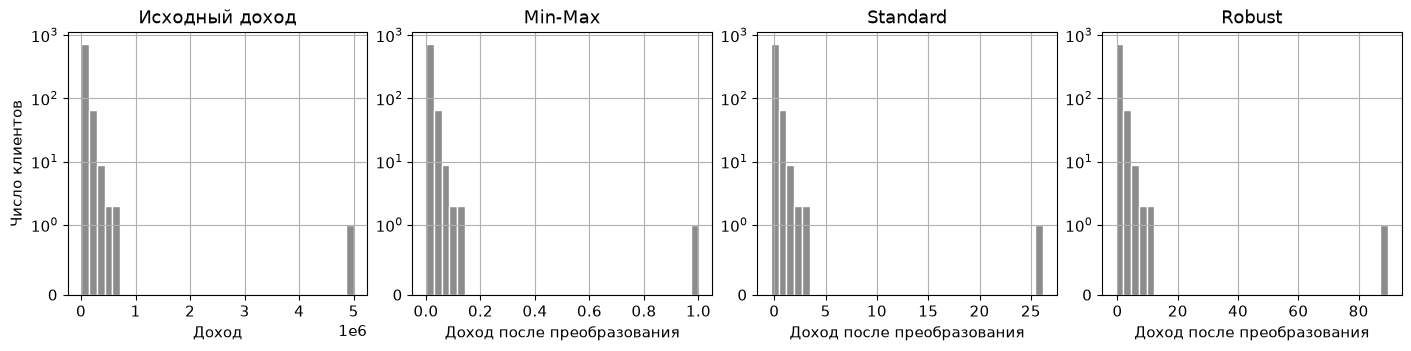

,Шкала,Межквартильный размах,Выброс
0,Исходный доход,55286.7500,5.000000e+06
1,Min-Max,0.0111,1.000000e+00
2,Standard,0.2938,2.620790e+01
3,Robust,1.0000,8.974870e+01


In [7]:
income = df[['Income']]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), layout='constrained')
scalers = [None, MinMaxScaler(), StandardScaler(), RobustScaler()]
titles = ['Исходный доход', 'Min-Max', 'Standard', 'Robust']
rows = []
for ax, title, scaler in zip(axes, titles, scalers):
    x = income['Income'].to_numpy() if scaler is None else scaler.fit_transform(income).ravel()
    ax.hist(x, bins=35, color='0.55', edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel('Доход' if scaler is None else 'Доход после преобразования')
    ax.set_yscale('symlog', linthresh=1)
    q1, q3 = np.percentile(x, [25, 75])
    rows.append([title, q3 - q1, x[0]])

axes[0].set_ylabel('Число клиентов')
plt.show()
display(pd.DataFrame(rows, columns=['Шкала', 'Межквартильный размах', 'Выброс']).round(4))


Ось частот на графиках имеет логарифмические деления, поэтому одиночный выброс виден рядом с большими частотами. Все три преобразования линейные и сохраняют форму распределения, включая правый хвост. Различается масштаб. Min-Max сильнее сжимает обычные доходы, так как выброс задаёт верхнюю границу 1. Standard тоже зависит от выброса через среднее и стандартное отклонение. У Robust центральные 50% имеют ширину 1, а выброс остаётся далеко справа. Для обработки дохода выбрал бы RobustScaler.

### 3.2 Выбор скейлера для каждого признака

In [8]:
scaler_choice = {
    'Age': 'StandardScaler',
    'Income': 'RobustScaler',
    'Tenure': 'MinMaxScaler',
    'CreditScore': 'StandardScaler',
}
justification = {
    'Age': 'Приводим возраст к общему масштабу с другими числовыми признаками.',
    'Income': 'Медиана и межквартильный размах устойчивы к единичному большому доходу.',
    'Tenure': 'Стаж ограничен диапазоном от 1 до 60 месяцев. Удобно привести его к шкале от 0 до 1 на train.',
    'CreditScore': 'Баллы на другой шкале. Стандартизация приводит их к сопоставимому масштабу.',
}
for col in num:
    print(f'{col}: {scaler_choice[col]}. {justification[col]}')


Age: StandardScaler. Приводим возраст к общему масштабу с другими числовыми признаками.
Income: RobustScaler. Медиана и межквартильный размах устойчивы к единичному большому доходу.
Tenure: MinMaxScaler. Стаж ограничен диапазоном от 1 до 60 месяцев. Удобно привести его к шкале от 0 до 1 на train.
CreditScore: StandardScaler. Баллы на другой шкале. Стандартизация приводит их к сопоставимому масштабу.


## 4 Кодирование категорий

### 4.1 Gender через LabelEncoder и One-Hot

In [9]:
gender_label = LabelEncoder().fit_transform(df['Gender'])
gender_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
display(df[['Gender']].assign(Gender_Label=gender_label).join(gender_ohe).head(8))


,Gender,Gender_Label,Gender_F,Gender_M
0,M,1,0,1
1,M,1,0,1
2,M,1,0,1
3,F,0,1,0
4,M,1,0,1
5,F,0,1,0
6,F,0,1,0
7,F,0,1,0


Здесь категорий две. Код 0/1 допустим для дерева решений и может использоваться как один бинарный индикатор в логистической регрессии. Для номинального признака с тремя и более категориями коды 0, 1, 2 создают искусственный порядок. Это особенно важно для линейных моделей и моделей на расстояниях. Для них обычно подходит One-Hot. В рабочем пайплайне для признаков используем OneHotEncoder, а LabelEncoder здесь нужен для демонстрации.

### 4.2 Порядок уровней Education

In [10]:
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
edu = df[['Education']]
ord_encoder = OrdinalEncoder(categories=[edu_order])
display(edu.assign(
    Явный_порядок=ord_encoder.fit_transform(edu).ravel().astype(int),
    По_умолчанию=OrdinalEncoder().fit_transform(edu).ravel().astype(int),
).drop_duplicates().sort_values('Явный_порядок'))


,Education,Явный_порядок,По_умолчанию
2,High School,0,1
3,Bachelor,1,0
0,Master,2,2
19,PhD,3,3


Без заданного списка категории отсортировались бы по алфавиту. Bachelor получил бы 0, High School — 1, Master — 2 и PhD — 3. Первые два уровня оказались бы в обратном порядке.

### 4.3 Частотное кодирование City

In [11]:
freq = df['City'].value_counts()
display(df[['City']].assign(City_Freq=df['City'].map(freq)).drop_duplicates().sort_values('City_Freq'))


,City,City_Freq
0,Ufa,115
16,Kazan,133
7,Moscow,135
1,Ekaterinburg,138
5,Novosibirsk,139
3,SPb,140


Города с одинаковым числом наблюдений получают один код. Их уже нельзя отличить по этому признаку. Это критично, если два одинаково представленных города сильно различаются по оттоку. При обучении частоты нужно считать по train и отдельно обрабатывать новые города.

## 5 ColumnTransformer

### 5.1 Сборка и проверка препроцессинга

Сначала откладываем тестовую часть. Преобразования из предыдущих разделов служили для демонстрации и не добавлялись в исходную таблицу признаков.

In [12]:
X = df[cols]
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer([
    ('std', StandardScaler(), ['Age', 'CreditScore']),
    ('robust', RobustScaler(), ['Income']),
    ('minmax', MinMaxScaler(), ['Tenure']),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), nom),
    ('ordinal', OrdinalEncoder(categories=[edu_order]), ord_cols),
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
print('Train:', X_train.shape, '->', X_train_prepared.shape)
print('Test: ', X_test.shape, '->', X_test_prepared.shape)
print(preprocessor.get_feature_names_out())
assert X_train_prepared.shape == (600, 11)
assert X_test_prepared.shape == (200, 11)


Train: (600, 7) -> (600, 11)
Test:  (200, 7) -> (200, 11)
['std__Age' 'std__CreditScore' 'robust__Income' 'minmax__Tenure'
 'onehot__Gender_M' 'onehot__City_Kazan' 'onehot__City_Moscow'
 'onehot__City_Novosibirsk' 'onehot__City_SPb' 'onehot__City_Ufa'
 'ordinal__Education']


1. При `fit_transform` на train запоминаются средние, квантили и категории. На test вызываем только `transform`, чтобы тестовая выборка не влияла на эти параметры.
2. Из двух значений Gender после удаления первой категории остаётся один столбец, из шести городов — пять.
3. По умолчанию неизвестный город приводит к ошибке. В нашем преобразователе стоит `handle_unknown='ignore'`. Тогда в городском блоке будут нули, как у первой, удалённой категории. Если нужно различать базовый и неизвестный город, можно выделить неизвестные в отдельную категорию при подготовке данных.

## 6 Выборки

### 6.1 Случайная и стратифицированная выборки

При стратификации сначала берём целую часть от размера каждой группы. Оставшиеся места достаются группам с наибольшими дробными остатками. Так размер выборки точно равен 100.

In [13]:
def stratified_sample(df, strat_col, n_total, random_state=42):
    quota = df[strat_col].value_counts(normalize=True) * n_total
    counts = quota.astype(int)
    missing = n_total - counts.sum()
    for group in (quota - counts).nlargest(missing).index:
        counts.loc[group] += 1

    rng = np.random.RandomState(random_state)
    parts = []
    for group, n in counts.items():
        rows = df[df[strat_col] == group]
        parts.append(rows.sample(n=n, random_state=rng))
    return pd.concat(parts).sample(frac=1, random_state=rng)

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', 100)
assert len(s_rand) == len(s_strat) == 100
assert s_strat.index.is_unique

base = df['Churn'].mean()
for name, sample in [('Все данные', df), ('Случайная', s_rand), ('Стратифицированная', s_strat)]:
    rate = sample['Churn'].mean()
    print(f'{name}: Churn = {rate:.3f}, отклонение = {abs(rate - base):.3f}')


Все данные: Churn = 0.371, отклонение = 0.000
Случайная: Churn = 0.320, отклонение = 0.051
Стратифицированная: Churn = 0.370, отклонение = 0.001


Стратифицированная выборка дала 37%, случайная дала 32%, а во всех данных 37,125%. Она сохраняет пропорции по `Churn` с учётом округления, но не обязана точно сохранять пропорции по другим признакам. `Churn` используется для разбиения, а в `X` его включать нельзя. Иначе модель получит правильный ответ среди входных данных.

### 6.2 Размер выборки и разброс медианы

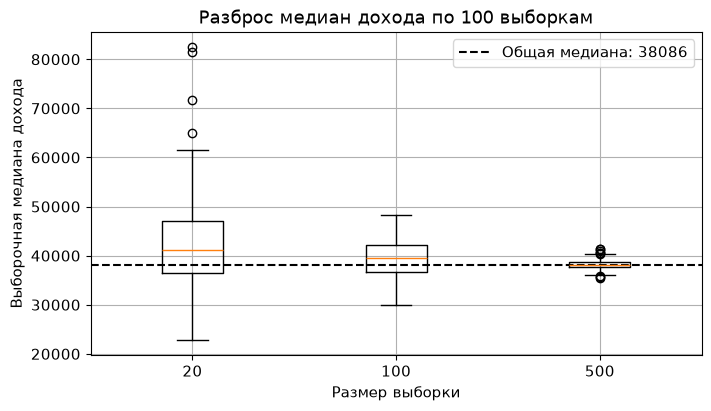

n = 20: стандартное отклонение медиан = 10444
n = 100: стандартное отклонение медиан = 3906
n = 500: стандартное отклонение медиан = 1144


In [14]:
sizes = [20, 100, 500]
results = {}
for n in sizes:
    medians = []
    for seed in range(100):
        medians.append(df.sample(n=n, random_state=seed)['Income'].median())
    results[n] = medians

median_all = df['Income'].median()
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.boxplot([results[n] for n in sizes])
ax.set_xticks([1, 2, 3], labels=[str(n) for n in sizes])
ax.axhline(median_all, color='black', linestyle='--', label=f'Общая медиана: {median_all:.0f}')
ax.set(title='Разброс медиан дохода по 100 выборкам',
       xlabel='Размер выборки', ylabel='Выборочная медиана дохода')
ax.legend()
plt.show()
for n in sizes:
    print(f'n = {n}: стандартное отклонение медиан = {np.std(results[n], ddof=1):.0f}')


Стандартное отклонение оценок медианы снизилось с 10 444 при n = 20 до 3 906 при n = 100 и до 1 144 при n = 500. Это согласуется с общей идеей уменьшения ошибки примерно как 1/√n. Формула σ/√n относится к среднему при независимых наблюдениях. Для медианы коэффициент зависит от плотности около неё. Кроме того, 500 строк — большая доля от 800, поэтому при отборе без возвращения разброс уменьшается сильнее.

Если считать среднее, попадание клиента с доходом 5 млн сдвигало бы оценку вверх, особенно в выборках по 20 строк. Медиана мало меняется от одного крайнего значения.

## Вывод

Для дохода выбран RobustScaler, для городов и пола — One-Hot, для образования — кодирование с заданным порядком. Обучение преобразований на train позволило получить 11 признаков без использования тестовых данных в `fit`. Стратификация лучше сохранила долю ушедших клиентов, а большие выборки дали более устойчивую оценку медианы дохода.